# Calibrating a multispectral camera: from DN to reflectance on real images

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_altum_en.ipynb)

**OpenSkyLab · notebook for the visual** [Calibrating a multispectral camera](https://openskylab.space/edu_viz_multispectral_calibration.html) · [česká verze](multispectral_calibration_altum_cs.ipynb)

The visual shows what a cloud, drone tilt, vignetting and a small panel do to reflectance. Here you go through the whole chain on real images from a MicaSense Altum camera: an image of the calibration panel before the flight and an image from the flight over a road junction, a forest, a row of trees and a grass field. Everything you need (black level, vignetting, calibration coefficients, panel reflectance, readings of the DLS 2 light sensor) is stored directly in the TIFF files.

**Goal:** convert DN to radiance step by step, compute the calibration coefficient from the panel, compare reflectance from the panel only, from the DLS only and from both, show the effect of vignetting, saturation and DLS tilt, and compute NDVI from co-registered bands.

**Data:** two captures (5 multispectral bands) from a MicaSense Altum camera with DLS 2 from the MicaSense sample data (repository micasense/imageprocessing, MIT licence): IMG_0000 (RP06 panel, 6 April 2022 20:00 UTC) and IMG_0021 (flight 2 minutes later about 100 m above ground), 47.70° N, 122.14° W. The Altum also has a thermal band 6, which this notebook does not use.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and images

In [1]:
import re, io, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from matplotlib.path import Path

BASE = "https://media.githubusercontent.com/media/micasense/imageprocessing/master/data/ALTUM/"
def fetch(name, tries=5):
    for i in range(tries):
        try:
            r = requests.get(BASE + name, timeout=120); r.raise_for_status(); return r.content
        except requests.RequestException as e:
            print(name, type(e).__name__, "– retrying"); time.sleep(3 * (i + 1))
    raise RuntimeError("Could not download the images.")

def xmp_reader(raw):
    x = raw[raw.find(b"<x:xmpmeta"): raw.find(b"</x:xmpmeta>")].decode()
    def get(tag):
        m = re.search(rf"<{tag}>(.*?)</{tag}>", x, re.S)
        if not m: return None
        v = m.group(1)
        if "<rdf:li>" in v:
            return [float(s) for li in re.findall(r"<rdf:li>\s*([^<]+?)\s*</rdf:li>", v) for s in li.split(",")]
        try: return float(v)
        except ValueError: return v.strip()
    return get

def load(name):
    """Load one band: the DN array and a dictionary of EXIF and XMP metadata."""
    raw = fetch(name); im = Image.open(io.BytesIO(raw)); ex = im.getexif(); sub = ex.get_ifd(0x8769); g = xmp_reader(raw)
    m = dict(band=g("Camera:BandName"), wl=g("Camera:CentralWavelength"), exposure=float(sub[33434]), gain=sub.get(34867, 100) / 100,
             black=float(np.mean(ex[50714])), bits=ex[258], cal=g("MicaSense:RadiometricCalibration"),
             vig_c=g("Camera:VignettingCenter"), vig_p=g("Camera:VignettingPolynomial"),
             vig_2d=g("Camera:VignettingPolynomial2D"), vig_e=g("Camera:VignettingPolynomial2DName"),
             albedo=g("Camera:Albedo"), area=g("Camera:ReflectArea"), time=ex[306],
             E_h=g("DLS:HorizontalIrradiance"), E_sensor=g("DLS:SpectralIrradiance"), E_dir=g("DLS:DirectIrradiance"),
             E_sc=g("DLS:ScatteredIrradiance"), sun_el=g("DLS:SolarElevation"), sun_az=g("DLS:SolarAzimuth"),
             pitch=g("DLS:Pitch"), roll=g("DLS:Roll"))
    for k in ("E_h", "E_sensor", "E_dir", "E_sc"):
        m[k] = m[k] * 0.01            # DLS 2 stores µW/cm²/nm; convert to W/m²/nm (factor 0.01 as in the MicaSense library)
    return np.array(im).astype(float), m

def vig_factor(m, shape):
    """Vignetting correction factor V for every pixel: a radial polynomial or, for newer cameras, a 2D polynomial (as in micasense/image.py)."""
    y, x = np.indices(shape)
    if m["vig_c"] is not None:
        return 1 / np.polyval(list(m["vig_p"])[::-1] + [1.0], np.hypot(x - m["vig_c"][0], y - m["vig_c"][1]))
    xv, yv = x / shape[1], y / shape[0]
    return 1 / sum(c * xv ** m["vig_e"][2 * i] * yv ** m["vig_e"][2 * i + 1] for i, c in enumerate(m["vig_2d"]))

def panel_shift(a, c):
    """Whole-pixel shift of image c relative to a by phase correlation."""
    f = np.fft.fft2(a - a.mean()) * np.conj(np.fft.fft2(c - c.mean())); cc = np.abs(np.fft.ifft2(f / (np.abs(f) + 1e-9)))
    dy, dx = np.unravel_index(cc.argmax(), cc.shape)
    return (dy - a.shape[0] if dy > a.shape[0] // 2 else dy, dx - a.shape[1] if dx > a.shape[1] // 2 else dx)

PANEL = {b: load(f"IMG_0000_{b}.tif") for b in range(1, 6)}
FLIGHT = {b: load(f"IMG_0021_{b}.tif") for b in range(1, 6)}
for b in PANEL:                     # if the camera software did not find the panel in some band, shift the area from band 1
    if PANEL[b][1]["area"] is None:
        dy, dx = panel_shift(PANEL[1][0], PANEL[b][0])
        PANEL[b][1]["area"] = list((np.array(PANEL[1][1]["area"]).reshape(-1, 2) - [dx, dy]).ravel())
        print(f"band {b}: panel area missing in the metadata, derived from band 1 by a shift of {dx}, {dy} px")
    if PANEL[b][1]["albedo"] is None:          # the panel reflectance is missing too: estimate by interpolation in wavelength from the other bands
        known = sorted((PANEL[k][1]["wl"], PANEL[k][1]["albedo"]) for k in PANEL if PANEL[k][1]["albedo"] is not None)
        PANEL[b][1]["albedo"] = float(np.interp(PANEL[b][1]["wl"], *zip(*known)))
        print(f"band {b}: panel reflectance missing in the metadata, interpolated estimate {PANEL[b][1]['albedo']:.3f}")
print(pd.DataFrame({PANEL[b][1]["band"]: {"λ (nm)": PANEL[b][1]["wl"], "exposure panel (ms)": 1000 * PANEL[b][1]["exposure"],
      "exposure flight (ms)": 1000 * FLIGHT[b][1]["exposure"], "panel reflectance": PANEL[b][1]["albedo"]} for b in PANEL}).round(3))
print("panel:", PANEL[1][1]["time"], " flight:", FLIGHT[1][1]["time"], " (UTC)")

band 2: panel area missing in the metadata, derived from band 1 by a shift of -125, -18 px
band 2: panel reflectance missing in the metadata, interpolated estimate 0.488
                         Blue    Green      Red      NIR  Red edge
λ (nm)                475.000  560.000  668.000  840.000   717.000
exposure panel (ms)     0.424    0.424    1.026    0.758     1.427
exposure flight (ms)    1.472    1.093    1.383    1.316     1.294
panel reflectance       0.488    0.488    0.487    0.485     0.486
panel: 2022:04:06 20:00:32  flight: 2022:04:06 20:02:49  (UTC)


## 2. From DN to radiance

The MicaSense model (the same as in the library `micasense/image.py`):

L = V(r) · R(y) · (DN − black level) / (gain · exposure) · a₁ / 2¹⁶

- black level: the signal without light (BlackLevel tag),
- V(r) = 1 / (1 + k₀r + … + k₅r⁶): vignetting correction by the distance r from the vignetting centre (newer cameras store a 2D polynomial in x, y instead),
- R(y) = 1 / (1 + a₂ y / exposure − a₃ y): correction by row (the sensor is read out row by row),
- a₁: the factory radiometric calibration coefficient. The result is spectral radiance in W/m²/sr/nm.

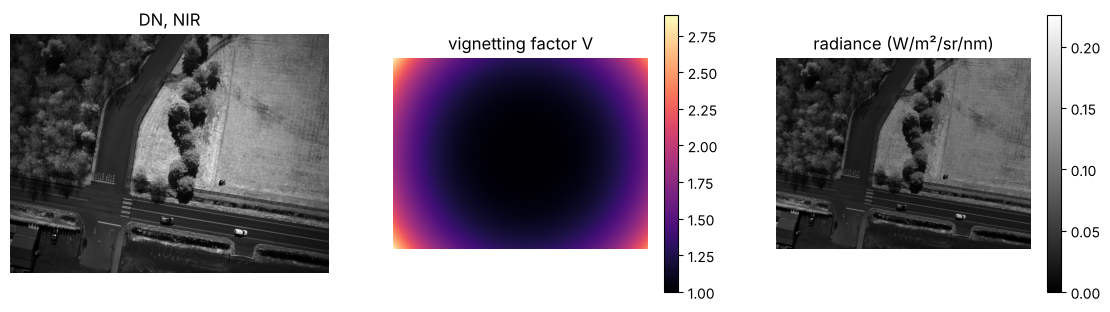

NIR: black level 4800 DN, exposure 1.32 ms, gain 1×
vignetting: centre ×1.00, corner ×2.89;  saturated pixels 0.00 %


In [2]:
def radiance(dn, m, vignette=True):
    y, x = np.indices(dn.shape)
    a1, a2, a3 = m["cal"]
    V = vig_factor(m, dn.shape) if vignette else 1.0
    R = 1 / (1 + a2 * y / m["exposure"] - a3 * y)
    return np.clip(V * R * (dn - m["black"]), 0, None) / (m["gain"] * m["exposure"]) * a1 / 2 ** m["bits"]

BAND = 4                      # ◀ parameter: band 1 blue, 2 green, 3 red, 4 NIR, 5 red edge
dn, m = FLIGHT[BAND]
y, x = np.indices(dn.shape)
V = vig_factor(m, dn.shape)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].imshow(dn, cmap="gray"); ax[0].set_title(f"DN, {m['band']}")
im = ax[1].imshow(V, cmap="magma"); plt.colorbar(im, ax=ax[1]); ax[1].set_title("vignetting factor V")
im = ax[2].imshow(radiance(dn, m), cmap="gray"); plt.colorbar(im, ax=ax[2]); ax[2].set_title("radiance (W/m²/sr/nm)")
for a in ax: a.axis("off")
plt.show()
sat = (dn >= 2 ** m["bits"] - 16).mean() * 100
print(f"{m['band']}: black level {m['black']:.0f} DN, exposure {m['exposure'] * 1000:.2f} ms, gain {m['gain']:.0f}×")
print(f"vignetting: centre ×{V.min():.2f}, corner ×{V[0, 0]:.2f};  saturated pixels {sat:.2f} %")

> **✏️ Task 1.** Go through bands 1 to 5. By what percentage does the vignetting correction boost the signal in the corner of the image, and in which band most? What percentage of pixels is saturated and where in the image are they? Why can no calibration fix a saturated pixel, and what do you do about it during the flight?

*Your answer:* 

## 3. The calibration panel

The metadata of the panel image contain an area in the middle of the panel that the camera software found in the image (ReflectArea, four corners in pixels), and its reflectance in the given band (Albedo) from the calibration sheet. The mean radiance of the panel L_p gives the coefficient k = ρ_panel / L_p and the reflectance of every pixel ρ = k · L.

           pixels     L_p  variability (%)  ρ_panel  k = ρ/L_p
Blue      15174.0  0.1963           1.7196   0.4884     2.4885
Green     15174.0  0.2035           1.6389   0.4877     2.3963
Red       15144.0  0.1766           1.7422   0.4868     2.7562
NIR       14910.0  0.1147           1.7565   0.4853     4.2323
Red edge  15156.0  0.1467           1.6920   0.4864     3.3147


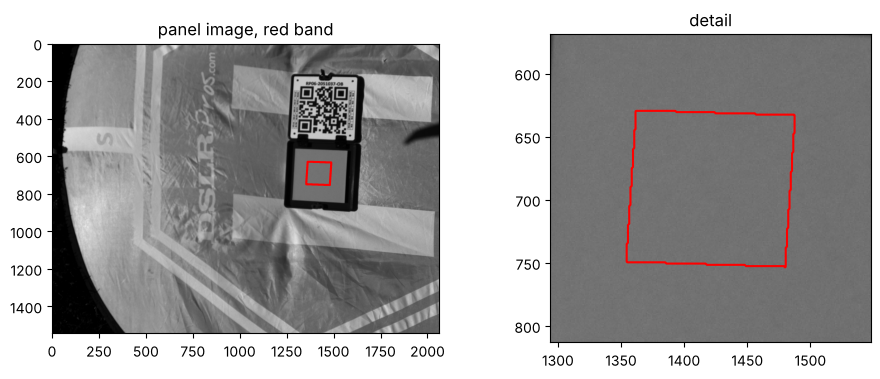

In [3]:
SHRINK = 1.0                  # ◀ parameter: shrink the area from the metadata (1 = the whole area, 0.3 = only the centre)
GROW_PX = 0                   # ◀ parameter: enlarge the area by this many pixels instead (imitates a sloppily marked panel)

def panel_mask(m, shrink=SHRINK, grow=GROW_PX):
    xy = np.array(m["area"]).reshape(-1, 2); c = xy.mean(axis=0)
    xy = c + (xy - c) * shrink + np.sign(xy - c) * grow
    yy, xx = np.indices(PANEL[1][0].shape)
    return Path(xy).contains_points(np.c_[xx.ravel(), yy.ravel()]).reshape(PANEL[1][0].shape)

rows = {}
for b, (dn, m) in PANEL.items():
    L = radiance(dn, m); msk = panel_mask(m)
    rows[m["band"]] = {"pixels": msk.sum(), "L_p": L[msk].mean(), "variability (%)": 100 * L[msk].std() / L[msk].mean(),
                       "ρ_panel": m["albedo"], "k = ρ/L_p": m["albedo"] / L[msk].mean()}
panel_tab = pd.DataFrame(rows).T
print(panel_tab.round(4))
dn, m = PANEL[3]
xy = np.array(m["area"]).reshape(-1, 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(radiance(dn, m), cmap="gray"); ax[0].contour(panel_mask(m), [0.5], colors="r"); ax[0].set_title("panel image, red band")
ax[1].imshow(radiance(dn, m), cmap="gray"); ax[1].contour(panel_mask(m), [0.5], colors="r")
ax[1].set_xlim(xy[:, 0].min() - 60, xy[:, 0].max() + 60); ax[1].set_ylim(xy[:, 1].max() + 60, xy[:, 1].min() - 60); ax[1].set_title("detail")
plt.show()

> **✏️ Task 2.** Set GROW_PX to 30, 60 and 90 (look at the detail to see how far the area reaches): how do the mean panel radiance and the coefficient k change? By what percentage would that shift the reflectance of the whole map? Then set SHRINK = 0.2: what happens to the variability and why? Why are only pixels from the centre of the panel averaged, and why must the panel be large enough in the image (how many pixels does it have here)?

*Your answer:* 

## 4. The DLS light sensor and its tilt

The DLS measures irradiance on its top surface. When the drone tilts towards the Sun, the sensor receives more direct radiation than the horizontal ground does. DLS 2 therefore splits irradiance into a direct and a diffuse component and converts it to a horizontal surface: E_hor = E_direct · sin(solar elevation) + E_diffuse.

In [4]:
TILT = 10                     # ◀ parameter: tilt of the DLS sensor (°)
rows = {}
for b in range(1, 6):
    for name, (dn, m) in [("panel", PANEL[b]), ("flight", FLIGHT[b])]:
        rows[(m["band"], name)] = {"E sensor": m["E_sensor"], "E horizontal": m["E_h"], "direct·sin(h)+diffuse": m["E_dir"] * np.sin(m["sun_el"]) + m["E_sc"],
                                   "tilt (°)": np.degrees(np.hypot(m["pitch"], m["roll"]))}
print(pd.DataFrame(rows).T.round(3))
m = FLIGHT[3][1]; el = m["sun_el"]
for direction, sign in [("towards the Sun", 1), ("away from the Sun", -1)]:
    cos_g = np.sin(el) * np.cos(np.radians(TILT)) + sign * np.cos(el) * np.sin(np.radians(TILT))
    E_tilt = m["E_dir"] * cos_g + m["E_sc"]
    print(f"solar elevation {np.degrees(el):.1f}°, tilt {TILT}° {direction}: the sensor measures {E_tilt / m['E_h']:.3f}× the horizontal irradiance (without correction a reflectance error of {100 * (m['E_h'] / E_tilt - 1):+.1f} %)")

                 E sensor  E horizontal  direct·sin(h)+diffuse  tilt (°)
Blue     panel      0.947         0.911                  0.911     6.973
         flight     1.289         1.122                  1.122     4.974
Green    panel      0.898         0.844                  0.844     6.973
         flight     1.209         1.050                  1.050     4.974
Red      panel      0.837         0.754                  0.754     6.973
         flight     1.080         0.939                  0.939     4.974
NIR      panel      0.495         0.455                  0.455     6.973
         flight     0.657         0.569                  0.569     4.974
Red edge panel      0.583         0.542                  0.542     6.973
         flight     0.787         0.680                  0.680     4.974
solar elevation 49.0°, tilt 10° towards the Sun: the sensor measures 1.108× the horizontal irradiance (without correction a reflectance error of -9.7 %)
solar elevation 49.0°, tilt 10° away from th

> **✏️ Task 3.** By what percentage did the horizontal irradiance change between the panel image and the flight image (the first cell printed the image times)? How large a reflectance error does a tilt of 10° and 20° towards and away from the Sun cause? Why is the error larger with a low Sun, and why does a large diffuse component (overcast) help?

*Your answer:* 

## 5. Three ways to calibrate

- **panel only:** ρ = k · L. Assumes the illumination has not changed since the panel image.
- **DLS only:** ρ = π · L / E_hor. Relies on the factory calibration of both the camera and the DLS.
- **panel + DLS:** ρ = k · L · E_hor(panel) / E_hor(image). The panel sets the absolute level, the DLS tracks changes in illumination.

Check: when we apply the “DLS only” method to the panel itself, we should get its known reflectance.

                            Blue  Green    Red  Red edge    NIR
forest        DLS only     0.012  0.030  0.024     0.100  0.175
              panel + DLS  0.009  0.019  0.016     0.057  0.107
              panel only   0.011  0.024  0.020     0.072  0.134
grass field   DLS only     0.005  0.035  0.004     0.147  0.540
              panel + DLS  0.003  0.023  0.003     0.084  0.331
              panel only   0.004  0.028  0.003     0.105  0.414
panel (check) DLS only     0.677  0.758  0.736     0.851  0.792
road          DLS only     0.083  0.105  0.109     0.132  0.144
              panel + DLS  0.060  0.067  0.072     0.075  0.088
              panel only   0.074  0.084  0.090     0.095  0.110


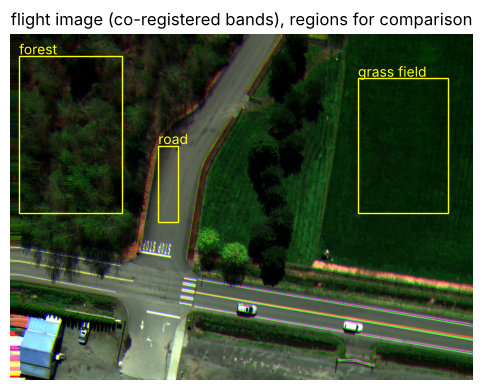

In [5]:
def shift_to(ref, img):
    """Whole-pixel shift of img relative to ref by phase correlation of gradients (each band has its own lens)."""
    g = lambda a: np.hypot(*np.gradient(ndi.gaussian_filter(a, 1.5)))
    F = np.fft.fft2(g(ref)) * np.conj(np.fft.fft2(g(img))); c = np.fft.ifft2(F / (np.abs(F) + 1e-12)).real
    dy, dx = np.unravel_index(c.argmax(), c.shape)
    return (dy - c.shape[0] if dy > c.shape[0] // 2 else dy, dx - c.shape[1] if dx > c.shape[1] // 2 else dx)

L_fl = {b: radiance(*FLIGHT[b]) for b in FLIGHT}
shifts = {b: shift_to(L_fl[3], L_fl[b]) for b in FLIGHT}
L_al = {b: ndi.shift(L_fl[b], shifts[b], order=0, mode="nearest") for b in FLIGHT}
REGIONS = {"road": (slice(500, 840), slice(660, 750)), "grass field": (slice(200, 800), slice(1550, 1950)), "forest": (slice(100, 800), slice(40, 500))}  # ◀ parameter: regions (rows, columns)
res = {}
for b in FLIGHT:
    mp, mf = PANEL[b][1], FLIGHT[b][1]; k = panel_tab.loc[mp["band"], "k = ρ/L_p"]
    methods = {"panel only": k * L_al[b], "DLS only": np.pi * L_al[b] / mf["E_h"], "panel + DLS": k * L_al[b] * mp["E_h"] / mf["E_h"]}
    for meth, rho in methods.items():
        for reg, (r, c) in REGIONS.items():
            res[(reg, meth, mp["band"])] = np.median(rho[r, c])
    res[("panel (check)", "DLS only", mp["band"])] = np.pi * panel_tab.loc[mp["band"], "L_p"] / mp["E_h"]
RHO = pd.Series(res).unstack()[["Blue", "Green", "Red", "Red edge", "NIR"]]
print(RHO.round(3))
fig, ax = plt.subplots(figsize=(11, 4.5))
rgb = np.dstack([L_al[3], L_al[2], L_al[1]]); ax.imshow(np.clip(rgb / np.percentile(rgb, 99), 0, 1))
for reg, (r, c) in REGIONS.items():
    ax.add_patch(plt.Rectangle((c.start, r.start), c.stop - c.start, r.stop - r.start, fill=False, color="yellow")); ax.text(c.start, r.start - 8, reg, color="yellow")
ax.set_title("flight image (co-registered bands), regions for comparison"); ax.axis("off"); plt.show()

> **✏️ Task 4.** What panel reflectance does the “DLS only” method give, and by what percentage does it differ from the calibration sheet? Which method is the most reliable here and why? How much do “panel only” and “panel + DLS” differ, and why (go back to step 4)? Do the curves of the road, grass field and forest match what you know from spectral signatures?

*Your answer:* 

## 6. NDVI and what calibration does to it

NDVI = (ρ_NIR − ρ_R) / (ρ_NIR + ρ_R). We compare NDVI from radiance (no calibration), from the “panel + DLS” calibration, and from a calibration without vignetting correction.

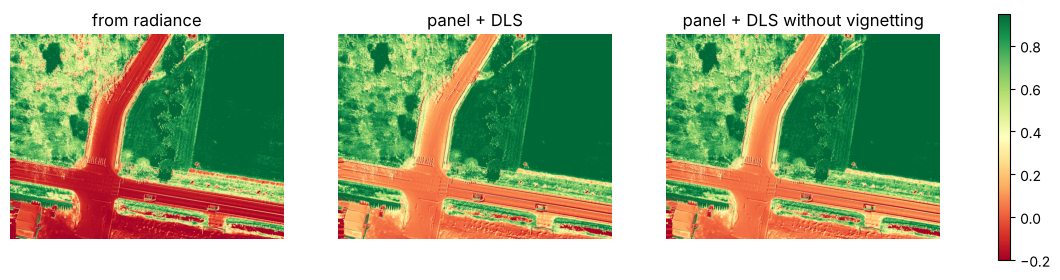

                      from radiance  panel + DLS  \
road                         -0.097        0.114   
grass field                   0.974        0.983   
forest                        0.644        0.752   
share NDVI ≥ 0.5 (%)         58.068       64.832   

                      panel + DLS without vignetting  
road                                           0.102  
grass field                                    0.984  
forest                                         0.733  
share NDVI ≥ 0.5 (%)                          64.376  


In [6]:
NDVI_MIN = 0.5                # ◀ parameter: NDVI threshold for “vegetation”
def calibrated(b, vignette=True):
    mp, mf = PANEL[b][1], FLIGHT[b][1]; k = panel_tab.loc[mp["band"], "k = ρ/L_p"]
    L = ndi.shift(radiance(*FLIGHT[b], vignette=vignette), shifts[b], order=0, mode="nearest")
    return k * L * mp["E_h"] / mf["E_h"]
nd = lambda nir, red: (nir - red) / (nir + red + 1e-9)
variants = {"from radiance": nd(L_al[4], L_al[3]), "panel + DLS": nd(calibrated(4), calibrated(3)),
            "panel + DLS without vignetting": nd(calibrated(4, False), calibrated(3, False))}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, v) in zip(ax, variants.items()):
    im = a.imshow(v, cmap="RdYlGn", vmin=-0.2, vmax=0.95); a.set_title(name); a.axis("off")
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()
print(pd.DataFrame({name: {**{reg: np.median(v[r, c]) for reg, (r, c) in REGIONS.items()}, f"share NDVI ≥ {NDVI_MIN} (%)": 100 * (v >= NDVI_MIN).mean()}
                    for name, v in variants.items()}).round(3))

> **✏️ Task 5.** Why does NDVI from radiance differ so much from NDVI from reflectance even though it is the same image? Why does skipping the vignetting correction hardly change NDVI while it does change reflectance in the corners (compare with step 2)? How would the vegetation share change if someone thresholded NDVI from radiance?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for another camera (RedEdge-MX, Altum, Altum-PT). Compare the panel coefficient k, the change in irradiance between the panel and the flight, and the difference between the “DLS only” and “panel + DLS” methods. Do the cameras differ more, or the lighting conditions during the flight?

*Your answer:* 

---
### Data sources and references

- Images and the radiometric calibration procedure: MicaSense, Inc. (2017–2023). *imageprocessing* (MIT licence), https://github.com/micasense/imageprocessing, files data/ALTUM/IMG_0000_*.tif and IMG_0021_*.tif and micasense/image.py (vignetting, radiance, reflectance).
- MicaSense: RedEdge Camera Radiometric Calibration Model; Use of Calibrated Reflectance Panels for MicaSense Data (MicaSense support).
- Smith, G. M., Milton, E. J. (1999). The use of the empirical line method to calibrate remotely sensed data to reflectance. *International Journal of Remote Sensing* 20(13), 2653–2662.
- Overview of UAV multispectral calibration: Aasen, H., Honkavaara, E., Lucieer, A., Zarco-Tejada, P. J. (2018). Quantitative remote sensing at ultra-high resolution with UAV spectroscopy. *Remote Sensing* 10(7), 1091.

### How to cite

OpenSkyLab (2026). Calibrating a multispectral camera: from DN to reflectance on real images [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/multispectral_calibration_altum_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*